# BAB 6.2 — MODEL DESIGN: ADVANCED MODEL (XGBOOST + TRUNCATED SVD + FITUR GAYA PENULISAN)

**Mata Kuliah:** Data Science (Semester 5)  
**Proyek:** Analisis Klasifikasi Ujaran Kebencian pada Informasi Pemerintahan Indonesia di Media Sosial Menggunakan Machine Learning dan Deep Learning  
**Keterkaitan SDG:** **SDG 16** (*Peace, Justice and Strong Institutions*) — Target 16.10 & 16.7  
**PIC / Anggota 2:** Muhammad Adam Al-Kidri (244311050)  
**Kolaborator / Anggota 1:** Ardhana Syah Hidayat (244311037)

---

### Tujuan Notebook:
1. **Justifikasi Teoretis Model 2 (Bab 6.2.1):** Menjelaskan prinsip *Gradient Tree Boosting*, alasan reduksi dimensi dengan TruncatedSVD sebelum pohon keputusan, serta keunggulan dan kelemahan XGBoost dibanding model linear.
2. **Perumusan Matematis (Bab 6.2.2):** Mendefinisikan ruang hipotesis aditif pohon \(\mathcal{H}\) dan tiga asumsi induktif utama: *axis-aligned partitioning*, *hierarchical feature interaction*, dan *regularization via shrinkage & tree constraints*.
3. **Feature Fusion Bebas Leakage:** Menggabungkan 100 komponen TruncatedSVD dari TF-IDF dengan 6 fitur gaya penulisan menjadi 106 fitur padat, dengan seluruh transformasi di-*fit* hanya pada Training Set.
4. **Pelatihan & Evaluasi Validasi (Bab 6.2.3):** Melatih XGBoost dengan konfigurasi awal dan mengevaluasi performa secara objektif pada **Validation Set** (`val.csv`).
5. **Interpretasi Model:** Menganalisis *feature importance* untuk melihat kontribusi fitur gaya penulisan, serta melakukan *error analysis* pada False Positive dan False Negative.


## 6.2.1 Teori Dasar, Keunggulan & Kelemahan XGBoost

### A. Prinsip Gradient Tree Boosting

XGBoost (*Extreme Gradient Boosting*) adalah ansambel aditif dari \(K\) pohon regresi CART (*Classification and Regression Tree*). Berbeda dari *Random Forest* yang membangun pohon secara paralel dan independen, XGBoost membangun pohon secara **sekuensial**: setiap pohon baru \(f_t\) dilatih untuk mengoreksi sisa kesalahan (*residual*) dari ansambel pohon sebelumnya.

Prediksi akhir model adalah jumlah skor seluruh pohon:

$$\hat{y}_i = \sum_{k=1}^{K} f_k(\mathbf{x}_i), \qquad f_k \in \mathcal{F}$$

dengan \(\mathcal{F}\) adalah ruang semua pohon regresi yang mungkin. Fungsi objektif yang diminimalkan terdiri dari dua komponen: kerugian pelatihan dan penalti kompleksitas pohon:

$$\mathcal{L}(\phi) = \sum_{i=1}^{N} l\left(y_i, \hat{y}_i\right) + \sum_{k=1}^{K} \Omega(f_k)$$

$$\Omega(f) = \gamma T + \frac{1}{2}\lambda \|w\|^2$$

dengan \(T\) = jumlah daun, \(w\) = vektor bobot daun, \(\gamma\) = penalti jumlah daun, dan \(\lambda\) = penalti besaran bobot daun (regulerisasi \(L_2\)).

Pada iterasi ke-\(t\), XGBoost menambahkan pohon \(f_t\) yang meminimalkan aproksimasi Taylor orde kedua dari objektif:

$$\tilde{\mathcal{L}}^{(t)} = \sum_{i=1}^{N} \left[ g_i f_t(\mathbf{x}_i) + \frac{1}{2} h_i f_t^2(\mathbf{x}_i) \right] + \Omega(f_t)$$

dengan \(g_i = \partial_{\hat{y}^{(t-1)}} l(y_i, \hat{y}^{(t-1)})\) dan \(h_i = \partial^2_{\hat{y}^{(t-1)}} l(y_i, \hat{y}^{(t-1)})\). Untuk partisi daun \(I_j\), bobot daun optimal adalah:

$$w_j^* = -\frac{\sum_{i \in I_j} g_i}{\sum_{i \in I_j} h_i + \lambda}$$

Sedangkan *gain* dari suatu kandidat split adalah:

$$\text{Gain} = \frac{1}{2}\left[ \frac{G_L^2}{H_L+\lambda} + \frac{G_R^2}{H_R+\lambda} - \frac{(G_L+G_R)^2}{H_L+H_R+\lambda} \right] - \gamma$$

dengan \(G_L, G_R\) = jumlah gradien di anak kiri/kanan dan \(H_L, H_R\) = jumlah Hessian di anak kiri/kanan. Split hanya dipilih jika *gain*-nya positif. Mekanisme inilah yang membuat XGBoost mampu menangkap interaksi non-linear antar-fitur dan melakukan seleksi fitur secara otomatis.

### B. Mengapa TruncatedSVD Diperlukan Sebelum Pohon Keputusan?

Matriks TF-IDF yang dihasilkan berukuran \(9.105 \times 5.000\) dengan tingkat *sparsity* **99,81%**. Pohon keputusan memilih split dengan menguji satu fitur pada satu waktu. Pada ruang 5.000 fitur *sparse*:

1. **Biaya komputasi split tinggi:** setiap kandidat fitur harus diurutkan/dipartisi; mayoritas fitur sangat jarang dan hanya aktif pada sedikit dokumen.
2. **Sinyal leksikal tersebar:** sinonim dan variasi kata yang jarang membuat sinyal kelas terpecah ke banyak kolom.
3. **Risiko *noise*:** fitur dengan frekuensi sangat rendah mudah menghasilkan split yang tidak general.

**TruncatedSVD** (setara *Latent Semantic Analysis* pada matriks TF-IDF) mendekomposisi matriks \(X\) menjadi:

$$X \approx U_k \Sigma_k V_k^T, \qquad Z = U_k \Sigma_k \in \mathbb{R}^{100}$$

Komponen \(Z\) adalah fitur laten padat yang merangkum pola ko-okurensi kata. Reduksi ke 100 dimensi mempercepat pencarian split, meredam *noise* leksikal, dan menghasilkan representasi kontinu yang lebih ramah untuk pohon.

> **Trade-off penting:** SVD adalah transformasi linear yang memutar ruang fitur. Pada data ini, 100 komponen hanya menjelaskan **23,45%** varians TF-IDF. Artinya, sebagian besar detail leksikal halus memang dibuang. Komponen SVD juga merupakan kombinasi linear dari banyak kata, sehingga tidak lagi bisa dibaca langsung sebagai "kata pemicu" seperti koefisien Logistic Regression.

### C. Feature Fusion: 100 Komponen SVD + 6 Fitur Gaya Penulisan

TF-IDF menangkap **apa yang ditulis**, tetapi tidak menangkap **bagaimana cara menulisnya**. Enam fitur gaya penulisan dari Bab 5 memberi sinyal meta-linguistik yang tidak tersedia dalam *bag-of-words*:

| Fitur | Makna | Sinyal yang Diharapkan |
| :--- | :--- | :--- |
| `char_length` | Panjang karakter | Cuitan panjang vs pendek |
| `word_count` | Jumlah kata | Kepadatan argumen |
| `caps_ratio` | Rasio huruf kapital | Emosi/teriakan |
| `exclamation_count` | Jumlah `!` dan `?` | Intensitas emosional |
| `user_mention_count` | Jumlah mention `USER` | Pola percakapan/debat |
| `abusive_lexicon_count` | Jumlah kata kasar | Sinyal leksikal eksplisit |

Penggabungan keduanya menghasilkan matriks \(9.105 \times 106\) yang padat. `StandardScaler` di-*fit* hanya pada Training Set agar skala tiap fitur seragam dan split pohon tidak didominasi fitur dengan rentang besar. Meskipun pohon secara teori invarian terhadap skala monoton, standardisasi membuat perbandingan *gain* antarfitur lebih stabil dan menjaga konsistensi pipeline dengan Bab 5.

### D. Keunggulan dan Kelemahan Dibanding Model Linear

| Aspek | Logistic Regression (Baseline) | XGBoost (Advanced) |
| :--- | :--- | :--- |
| **Hubungan fitur** | Linear pada log-odds | Non-linear, menangkap interaksi |
| **Ruang input** | 5.000 fitur *sparse* | 106 fitur padat hasil fusi |
| **Interpretasi** | Koefisien bertanda, arah jelas | *Gain importance*, tanpa arah pengaruh |
| **Optimasi** | Konveks, minimum global | Non-konveks, optimasi *greedy* |
| **Biaya latih** | Rendah | Lebih tinggi |
| **Risiko overfitting** | Terkendali oleh \(L_2\) | Lebih tinggi, sensitif hiperparameter |
| **Detail leksikal** | Utuh | Terkompresi oleh SVD |
| **Fitur campuran** | Tidak natural | Natural (SVD + numerik) |
| **Kalibrasi probabilitas** | Umumnya baik | Kurang stabil pada data kecil |

Keunggulan utama XGBoost adalah kemampuannya menangkap interaksi seperti "cuitan pendek + huruf kapital tinggi + kata kasar" yang tidak dapat direpresentasikan oleh model aditif linear. Kelemahan utamanya adalah hilangnya detail leksikal akibat SVD, interpretasi yang lebih kabur, dan risiko *overfitting* pada dataset berukuran sedang (~9 ribu baris).


## 6.2.2 Hypothesis Space & Inductive Bias

### A. Hypothesis Space (\(\mathcal{H}\))

Ruang hipotesis XGBoost adalah keluarga fungsi aditif yang tersusun dari \(K\) pohon regresi:

$$\mathcal{H} = \left\{ f(\mathbf{x}) = \sum_{k=1}^{K} f_k(\mathbf{x}) \;\middle|\; f_k \in \mathcal{F} \right\}$$

dengan setiap pohon \(f_k\) didefinisikan oleh struktur partisi \(q\) dan bobot daun \(w\):

$$\mathcal{F} = \left\{ f(\mathbf{x}) = w_{q(\mathbf{x})} \;\middle|\; q: \mathbb{R}^{106} \to \{1,\dots,T\}, \; \mathbf{w} \in \mathbb{R}^{T} \right\}$$

Pada konfigurasi awal, \(K = 100\) dan kedalaman maksimum \(6\), sehingga setiap pohon memiliki paling banyak \(T \le 2^6 = 64\) daun. Fungsi yang dihasilkan bersifat **piecewise constant** dan **aditif**, bukan satu hyperplane linear. Batas keputusannya merupakan gabungan dari kotak-kotak sejajar sumbu (*axis-aligned boxes*), bukan bidang datar tunggal seperti Logistic Regression.

### B. Inductive Bias (Asumsi Dasar Model)

1. **Axis-Aligned Partitioning (Partisi Sejajar Sumbu)**  
   Setiap split berbentuk \(x_j \le \theta\) pada satu fitur. Model mengasumsikan bahwa batas keputusan yang baik dapat didekati dengan potongan-potongan sejajar sumbu fitur. Konsekuensinya, XGBoost sangat efisien jika sinyal kelas bersifat monotonik terhadap fitur, tetapi kurang efisien jika batas keputusan miring (*oblique*) terhadap sumbu. Karena SVD memutar ruang TF-IDF, split sejajar sumbu pada 100 komponen SVD tidak selalu sejajar dengan sumbu kata asli — ini adalah salah satu alasan potensial mengapa model advanced bisa lebih lemah dari baseline linear pada teks.

2. **Hierarchical Feature Interaction (Interaksi Fitur Hierarkis)**  
   Setiap jalur dari akar ke daun dengan kedalaman \(d\) dapat menguji hingga \(d\) fitur secara berurutan. Dengan `max_depth=6`, satu pohon dapat merepresentasikan interaksi hingga orde 6 (mis. "kata kasar" **dan** "huruf kapital tinggi" **dan** "cuitan pendek"). Penjumlahan 100 pohon memperluas ruang interaksi ini. Inilah keunggulan utama XGBoost dibanding Logistic Regression yang hanya aditif.

3. **Regularization via Shrinkage & Tree Depth Constraint (Regularisasi melalui Penyusutan dan Batas Kedalaman)**  
   Setiap pohon baru diskalakan dengan `learning_rate=0.1` (*shrinkage*) agar kontribusinya kecil dan bertahap. Kedalaman dibatasi `max_depth=6`, jumlah pohon dibatasi 100, dan penalti \(\gamma T + \frac{1}{2}\lambda\|w\|^2\) menghukum pohon yang terlalu besar. Kombinasi ini merupakan **prior parsimoni**: model diarahkan ke fungsi yang sederhana dan stabil, bukan menghafal data latih. Pembobotan kelas `scale_pos_weight=1,366` juga merupakan bentuk prior terhadap distribusi kelas yang tidak seimbang.


In [1]:
import json
import re
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve
)

from IPython.display import display

SEED = 42
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

print("Library berhasil dimuat.")
print(f"XGBoost versi: {xgboost.__version__}")


Library berhasil dimuat.
XGBoost versi: 3.4.1


### Pemuatan Data & Verifikasi Integritas Fitur

Kita membaca `train.csv` dan `val.csv` hasil Bab 5. Data uji (`test.csv`) **tidak dimuat**. Enam fitur gaya penulisan sudah dihitung pada Bab 5 dari teks mentah; pada cell berikut kita **verifikasi ulang** nilainya dengan menghitung ulang dari kolom `Tweet` mentah, lalu membandingkannya dengan kolom yang tersimpan. Ini memastikan tidak ada salah hitung atau kebocoran fitur.


In [2]:
# Path adaptif proyek
current_dir = Path.cwd()
root_dir = current_dir if (current_dir / 'data').exists() else current_dir.parent
data_dir = root_dir / 'data' / 'processed'

train_df = pd.read_csv(data_dir / 'train.csv', keep_default_na=False)
val_df = pd.read_csv(data_dir / 'val.csv', keep_default_na=False)

print(f"Data Train      : {len(train_df):,} baris | Distribusi HS: {train_df['HS'].value_counts().to_dict()}")
print(f"Data Validation : {len(val_df):,} baris | Distribusi HS: {val_df['HS'].value_counts().to_dict()}")

TEXT_COL = 'text_clean_lexical'
STYLE_FEATURES = [
    'char_length',
    'word_count',
    'caps_ratio',
    'exclamation_count',
    'user_mention_count',
    'abusive_lexicon_count',
]

X_train_text = train_df[TEXT_COL]
y_train = train_df['HS'].values
X_val_text = val_df[TEXT_COL]
y_val = val_df['HS'].values

# Validasi kolom dan nilai
assert all(col in train_df.columns for col in STYLE_FEATURES)
assert all(col in val_df.columns for col in STYLE_FEATURES)
assert not train_df[STYLE_FEATURES].isna().any().any()
assert not val_df[STYLE_FEATURES].isna().any().any()
assert (train_df[STYLE_FEATURES].values >= 0).all()

# Verifikasi ulang 6 fitur dari teks mentah (sama dengan resep Bab 5)
abusive_df = pd.read_csv(root_dir / 'data' / 'raw' / 'abusive.csv', header=None, keep_default_na=False)
ABUSIVE = set(abusive_df[0].astype(str).str.lower().str.strip())

def recompute_style_features(raw_series):
    raw_series = raw_series.astype(str)
    return pd.DataFrame({
        'char_length': raw_series.str.len(),
        'word_count': raw_series.str.split().str.len(),
        'caps_ratio': raw_series.map(lambda s: sum(ch.isupper() for ch in s) / (len(s) + 1)),
        'exclamation_count': raw_series.str.count(r'[!?]'),
        'user_mention_count': raw_series.str.count(r'\bUSER\b'),
        'abusive_lexicon_count': raw_series.map(
            lambda s: sum(word in ABUSIVE for word in re.findall(r'[a-z]+', s.lower()))
        ),
    })

for split_name, split_df in [('train', train_df), ('val', val_df)]:
    recon = recompute_style_features(split_df['Tweet'])
    for col in STYLE_FEATURES:
        assert np.allclose(recon[col].values, split_df[col].values), f"{split_name}.{col} tidak cocok"

print("\nVerifikasi 6 fitur gaya penulisan: MATCH 100% dengan hitungan ulang dari Tweet mentah.")


Data Train      : 9,105 baris | Distribusi HS: {0: 5257, 1: 3848}
Data Validation : 1,951 baris | Distribusi HS: {0: 1127, 1: 824}



Verifikasi 6 fitur gaya penulisan: MATCH 100% dengan hitungan ulang dari Tweet mentah.


### Representasi TF-IDF (Fit Hanya pada Training Set)

Konfigurasi TF-IDF sengaja disamakan dengan baseline agar perbandingan Bab 6.3 bersifat *apples-to-apples*: unigram–bigram, 5.000 fitur, `min_df=2`, dan `sublinear_tf=True`. `TfidfVectorizer` hanya di-*fit* pada `train.csv`, lalu mentransformasi `val.csv` secara pasif.


In [3]:
t0 = time.perf_counter()

tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=5000,
    min_df=2,
    sublinear_tf=True,
)

X_train_tfidf = tfidf.fit_transform(X_train_text)
X_val_tfidf = tfidf.transform(X_val_text)

t_tfidf = time.perf_counter() - t0
sparsity = 1.0 - (X_train_tfidf.nnz / (X_train_tfidf.shape[0] * X_train_tfidf.shape[1]))

print(f"Dimensi Matriks Fitur Train : {X_train_tfidf.shape}")
print(f"Dimensi Matriks Fitur Val   : {X_val_tfidf.shape}")
print(f"Tingkat Sparsitas Matriks   : {sparsity:.4%}")
print(f"Waktu TF-IDF (detik)        : {t_tfidf:.3f}")


Dimensi Matriks Fitur Train : (9105, 5000)
Dimensi Matriks Fitur Val   : (1951, 5000)
Tingkat Sparsitas Matriks   : 99.8134%
Waktu TF-IDF (detik)        : 0.746


### Reduksi Dimensi dengan TruncatedSVD

`TruncatedSVD(n_components=100, random_state=42)` di-*fit* hanya pada matriks TF-IDF Training Set. Validation Set ditransformasi dengan komponen yang sama. Visualisasi berikut menunjukkan akumulasi varians yang dijelaskan; angka ini penting untuk menilai berapa banyak informasi leksikal yang dibuang.


Dimensi SVD Train : (9105, 100)
Dimensi SVD Val   : (1951, 100)
Total varians TF-IDF yang dijelaskan 100 komponen: 23.4455%
Waktu SVD (detik) : 1.724


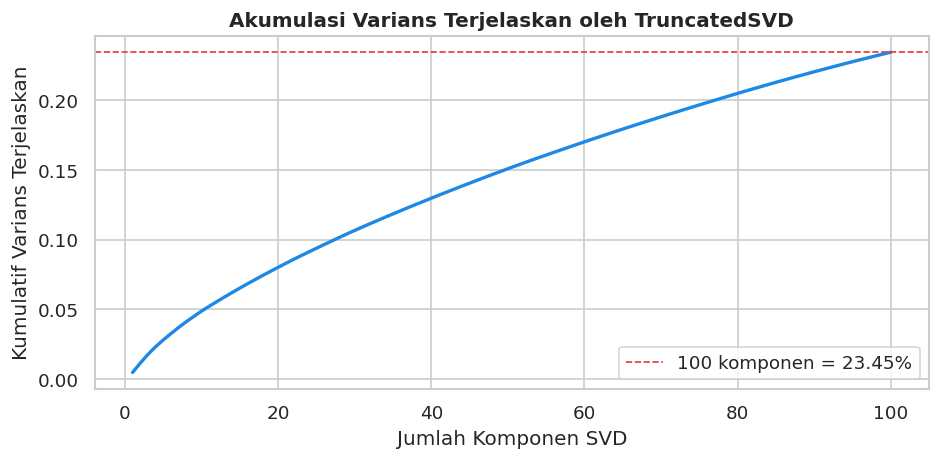

In [4]:
t0 = time.perf_counter()

svd = TruncatedSVD(n_components=100, random_state=SEED)
Z_train = svd.fit_transform(X_train_tfidf)
Z_val = svd.transform(X_val_tfidf)

t_svd = time.perf_counter() - t0
cum_var = np.cumsum(svd.explained_variance_ratio_)
explained_total = float(svd.explained_variance_ratio_.sum())

print(f"Dimensi SVD Train : {Z_train.shape}")
print(f"Dimensi SVD Val   : {Z_val.shape}")
print(f"Total varians TF-IDF yang dijelaskan 100 komponen: {explained_total:.4%}")
print(f"Waktu SVD (detik) : {t_svd:.3f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, 101), cum_var, color='#1E88E5', lw=2)
ax.axhline(y=explained_total, color='#E53935', linestyle='--', lw=1,
           label=f'100 komponen = {explained_total:.2%}')
ax.set_title('Akumulasi Varians Terjelaskan oleh TruncatedSVD', fontsize=12, fontweight='bold')
ax.set_xlabel('Jumlah Komponen SVD')
ax.set_ylabel('Kumulatif Varians Terjelaskan')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()


### Feature Fusion & Standardisasi (Fit Hanya pada Training Set)

Seratus komponen SVD digabung dengan enam fitur gaya penulisan menjadi 106 fitur padat. `StandardScaler` di-*fit* hanya pada Training Set; Validation Set ditransformasi dengan rata-rata dan standar deviasi Training Set. Cell berikut juga menguji bahwa rata-rata hasil transformasi Training Set mendekati nol.


In [5]:
t0 = time.perf_counter()

X_train_style = train_df[STYLE_FEATURES].to_numpy(dtype=float)
X_val_style = val_df[STYLE_FEATURES].to_numpy(dtype=float)

X_train_fused = np.hstack([Z_train, X_train_style])
X_val_fused = np.hstack([Z_val, X_val_style])

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_fused)
X_val_scaled = scaler.transform(X_val_fused)

t_scaler = time.perf_counter() - t0

assert X_train_scaled.shape[1] == 106
assert np.allclose(X_train_scaled.mean(axis=0), 0.0, atol=1e-9)
assert np.allclose(X_train_scaled.std(axis=0), 1.0, atol=1e-6)

print(f"Dimensi Fitur Fusi Train : {X_train_scaled.shape}")
print(f"Dimensi Fitur Fusi Val   : {X_val_scaled.shape}")
print(f"Waktu fusi + scaling (detik): {t_scaler:.3f}")
print("Cek scaler: mean Training Set = 0, std Training Set = 1 (OK)")


Dimensi Fitur Fusi Train : (9105, 106)
Dimensi Fitur Fusi Val   : (1951, 106)
Waktu fusi + scaling (detik): 0.053
Cek scaler: mean Training Set = 0, std Training Set = 1 (OK)


### Pelatihan XGBoost

Konfigurasi awal mengikuti rencana Minggu 3: 100 pohon, kedalaman 6, learning rate 0,1, dan `scale_pos_weight` sebesar rasio kelas negatif terhadap positif pada Training Set. Tidak ada *early stopping* pada konfigurasi awal; Validation Set tetap murni sebagai evaluator. *Early stopping* dijadwalkan pada iterasi tuning Minggu 4.


In [6]:
n_neg = int((y_train == 0).sum())
n_pos = int((y_train == 1).sum())
scale_pos_weight = n_neg / n_pos

print(f"Kelas 0 (Non-HS) : {n_neg:,}")
print(f"Kelas 1 (HS)     : {n_pos:,}")
print(f"scale_pos_weight : {scale_pos_weight:.4f}")

model = xgboost.XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    scale_pos_weight=scale_pos_weight,
    objective='binary:logistic',
    eval_metric='logloss',
    tree_method='hist',
    n_jobs=-1,
    random_state=SEED,
)

t0 = time.perf_counter()
model.fit(X_train_scaled, y_train)
t_xgb = time.perf_counter() - t0

y_val_pred = model.predict(X_val_scaled)
y_val_proba = model.predict_proba(X_val_scaled)[:, 1]

print(f"\nModel XGBoost berhasil dilatih.")
print(f"Waktu fit XGBoost (detik): {t_xgb:.3f}")


Kelas 0 (Non-HS) : 5,257
Kelas 1 (HS)     : 3,848
scale_pos_weight : 1.3662



Model XGBoost berhasil dilatih.
Waktu fit XGBoost (detik): 3.052


## 6.2.3 Hasil Evaluasi pada Validation Set

Evaluasi dilakukan murni pada `val.csv` ($N = 1.951$). Metrik utama yang diaudit adalah **Macro F1-Score**, **Precision Kelas 1 (HS)** untuk mengendalikan False Positive, **Recall Kelas 1 (HS)**, serta **ROC-AUC** dan **PR-AUC**.


In [7]:
macro_f1 = f1_score(y_val, y_val_pred, average='macro')
f1_hs = f1_score(y_val, y_val_pred, pos_label=1)
prec_hs = precision_score(y_val, y_val_pred, pos_label=1)
rec_hs = recall_score(y_val, y_val_pred, pos_label=1)
roc_auc = roc_auc_score(y_val, y_val_proba)
pr_auc = average_precision_score(y_val, y_val_proba)

cm = confusion_matrix(y_val, y_val_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

print("=" * 64)
print(f"HASIL EVALUASI ADVANCED MODEL PADA VALIDATION SET (N = {len(y_val):,})")
print("=" * 64)
print(f"Macro F1-Score              : {macro_f1:.4f} ({macro_f1:.2%})")
print(f"Precision Kelas 1 (HS)      : {prec_hs:.4f} ({prec_hs:.2%})")
print(f"Recall Kelas 1 (HS)         : {rec_hs:.4f} ({rec_hs:.2%})")
print(f"F1-Score Kelas 1 (HS)       : {f1_hs:.4f} ({f1_hs:.2%})")
print(f"ROC-AUC                     : {roc_auc:.4f} ({roc_auc:.2%})")
print(f"PR-AUC (Average Precision)  : {pr_auc:.4f} ({pr_auc:.2%})")
print("=" * 64)
print(f"Confusion Matrix: TN={tn}, FP={fp}, FN={fn}, TP={tp}")

print("\nLaporan Klasifikasi Rinci:")
print(classification_report(y_val, y_val_pred, target_names=['Non-Hate Speech (0)', 'Hate Speech (1)'], digits=4))


HASIL EVALUASI ADVANCED MODEL PADA VALIDATION SET (N = 1,951)
Macro F1-Score              : 0.8222 (82.22%)
Precision Kelas 1 (HS)      : 0.8055 (80.55%)
Recall Kelas 1 (HS)         : 0.7791 (77.91%)
F1-Score Kelas 1 (HS)       : 0.7921 (79.21%)
ROC-AUC                     : 0.9034 (90.34%)
PR-AUC (Average Precision)  : 0.8806 (88.06%)
Confusion Matrix: TN=972, FP=155, FN=182, TP=642

Laporan Klasifikasi Rinci:
                     precision    recall  f1-score   support

Non-Hate Speech (0)     0.8423    0.8625    0.8523      1127
    Hate Speech (1)     0.8055    0.7791    0.7921       824

           accuracy                         0.8273      1951
          macro avg     0.8239    0.8208    0.8222      1951
       weighted avg     0.8268    0.8273    0.8269      1951



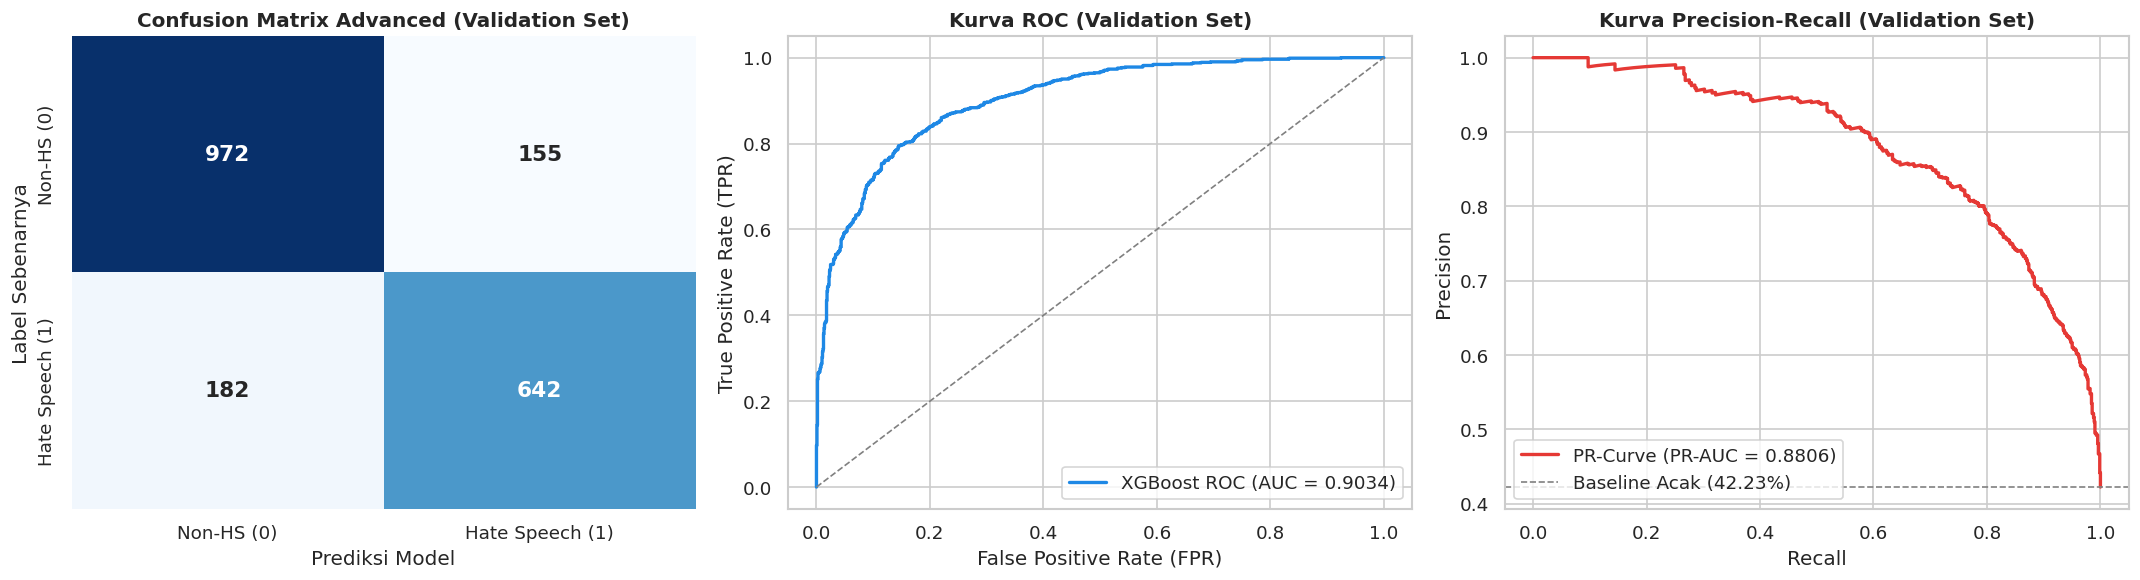

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Confusion Matrix
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    ax=axes[0],
    xticklabels=['Non-HS (0)', 'Hate Speech (1)'],
    yticklabels=['Non-HS (0)', 'Hate Speech (1)'],
    cbar=False,
    annot_kws={"size": 13, "weight": "bold"}
)
axes[0].set_title('Confusion Matrix Advanced (Validation Set)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Prediksi Model')
axes[0].set_ylabel('Label Sebenarnya')

# 2. Kurva ROC
fpr, tpr, _ = roc_curve(y_val, y_val_proba)
axes[1].plot(fpr, tpr, color='#1E88E5', lw=2, label=f'XGBoost ROC (AUC = {roc_auc:.4f})')
axes[1].plot([0, 1], [0, 1], color='grey', linestyle='--', lw=1)
axes[1].set_title('Kurva ROC (Validation Set)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('False Positive Rate (FPR)')
axes[1].set_ylabel('True Positive Rate (TPR)')
axes[1].legend(loc='lower right')

# 3. Kurva Precision-Recall
precision_pts, recall_pts, _ = precision_recall_curve(y_val, y_val_proba)
axes[2].plot(recall_pts, precision_pts, color='#E53935', lw=2, label=f'PR-Curve (PR-AUC = {pr_auc:.4f})')
axes[2].axhline(y=y_val.mean(), color='grey', linestyle='--', lw=1, label=f'Baseline Acak ({y_val.mean():.2%})')
axes[2].set_title('Kurva Precision-Recall (Validation Set)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Recall')
axes[2].set_ylabel('Precision')
axes[2].legend(loc='lower left')

plt.tight_layout()
plt.show()


### Analisis Feature Importance

XGBoost menyediakan *gain importance*: total pengurangan kerugian yang disumbangkan suatu fitur ketika digunakan untuk split. Berbeda dari koefisien Logistic Regression, nilai ini **tidak bertanda** — ia hanya menunjukkan besarnya kontribusi, bukan arah pengaruh. Kita akan memeriksa apakah keenam fitur gaya penulisan masuk ke 15 fitur teratas, serta berapa total porsi *gain* kelompok fitur gaya penulisan dibanding 100 komponen SVD.


Total gain (ternormalisasi): 1.0000
Porsi gain 6 fitur gaya penulisan: 8.83%
Fitur gaya penulisan di top 15: 3
 rank               feature     gain
    5    user_mention_count 0.021424
    7 abusive_lexicon_count 0.020317
    8           char_length 0.019694

Top 15 fitur berdasarkan gain:


,rank,feature,group,gain
0,1,SVD_008,Komponen SVD,0.043731
1,2,SVD_018,Komponen SVD,0.030078
2,3,SVD_005,Komponen SVD,0.025048
3,4,SVD_001,Komponen SVD,0.021527
4,5,user_mention_count,Gaya Penulisan,0.021424
5,6,SVD_056,Komponen SVD,0.020422
6,7,abusive_lexicon_count,Gaya Penulisan,0.020317
7,8,char_length,Gaya Penulisan,0.019694
8,9,SVD_017,Komponen SVD,0.017720
9,10,SVD_019,Komponen SVD,0.017064


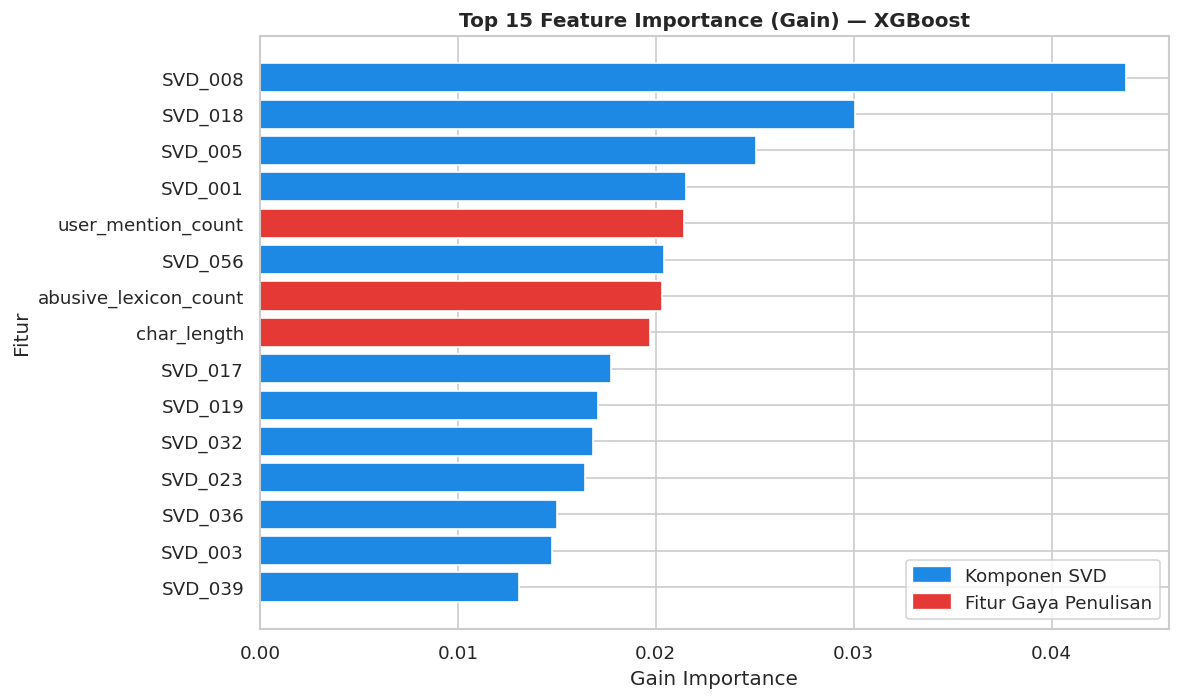

In [9]:
feature_names = np.array(
    [f'SVD_{i+1:03d}' for i in range(100)] + STYLE_FEATURES
)
importances = model.feature_importances_

imp_df = pd.DataFrame({
    'feature': feature_names,
    'gain': importances,
})
imp_df['group'] = np.where(
    imp_df['feature'].isin(STYLE_FEATURES),
    'Gaya Penulisan',
    'Komponen SVD'
)
imp_df = imp_df.sort_values('gain', ascending=False).reset_index(drop=True)
imp_df['rank'] = imp_df.index + 1

top15 = imp_df.head(15).copy()
style_top15 = top15[top15['group'] == 'Gaya Penulisan']
style_share = imp_df.loc[imp_df['group'] == 'Gaya Penulisan', 'gain'].sum() / imp_df['gain'].sum()

print(f"Total gain (ternormalisasi): {imp_df['gain'].sum():.4f}")
print(f"Porsi gain 6 fitur gaya penulisan: {style_share:.2%}")
print(f"Fitur gaya penulisan di top 15: {len(style_top15)}")
if len(style_top15) > 0:
    print(style_top15[['rank', 'feature', 'gain']].to_string(index=False))

print("\nTop 15 fitur berdasarkan gain:")
display(top15[['rank', 'feature', 'group', 'gain']])

colors = ['#E53935' if g == 'Gaya Penulisan' else '#1E88E5' for g in top15['group']]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top15['feature'][::-1], top15['gain'][::-1], color=colors[::-1])
ax.set_title('Top 15 Feature Importance (Gain) — XGBoost', fontsize=12, fontweight='bold')
ax.set_xlabel('Gain Importance')
ax.set_ylabel('Fitur')
from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(color='#1E88E5', label='Komponen SVD'),
    Patch(color='#E53935', label='Fitur Gaya Penulisan'),
], loc='lower right')
plt.tight_layout()
plt.show()


### Error Analysis: False Positive & False Negative

Sesuai `CONTEXT.md`, kita mengambil minimal 5 contoh False Positive (kritik wajar yang salah dicap ujaran kebencian) dan 5 False Negative (ujaran kebencian yang lolos). Contoh FP diurutkan dari probabilitas tertinggi (paling percaya diri salah), sedangkan FN dari probabilitas terendah (paling percaya diri salah).


In [10]:
val_analysis = val_df[['Tweet', 'text_clean_lexical', 'HS']].copy()
val_analysis['pred'] = y_val_pred
val_analysis['prob_hs'] = y_val_proba

fp_df = val_analysis[(val_analysis['HS'] == 0) & (val_analysis['pred'] == 1)].sort_values('prob_hs', ascending=False)
fn_df = val_analysis[(val_analysis['HS'] == 1) & (val_analysis['pred'] == 0)].sort_values('prob_hs', ascending=True)

pd.set_option('display.max_colwidth', 160)

print("=" * 70)
print("CONTOH FALSE POSITIVE (Aktual 0, Diprediksi 1)")
print("=" * 70)
display(fp_df.head(5)[['Tweet', 'text_clean_lexical', 'prob_hs']])

print("=" * 70)
print("CONTOH FALSE NEGATIVE (Aktual 1, Diprediksi 0)")
print("=" * 70)
display(fn_df.head(5)[['Tweet', 'text_clean_lexical', 'prob_hs']])


CONTOH FALSE POSITIVE (Aktual 0, Diprediksi 1)


,Tweet,text_clean_lexical,prob_hs
1197,Atas dasar hukum apa?,dasar hukum,0.974708
1119,RT USER: USER Aku inget dulu pernah pura pura sakit biar diperhatiin alias anjing bangsat jadi sakit beneran kan brengsek',pura pura sakit biar diperhatikan alias anjing bangsat sakit benaran berengsek,0.963310
799,USER bajingan tengik memang',bajingan tengik,0.943002
260,"USER Mengadu ke Allah agar para pemimpin yang bejat,bangsat,bajingan segera bertaubat kepada Allah dan kembali ke jalan Allah.'",mengadu allah pemimpin bejat bangsat bajingan bertobat allah jalan allah,0.937751
1576,Kita Cinta Indonesia; #2019KitaTetapJokowi; #KitaJokowi; #2019TetapJokowi ; #M3nang,cinta indonesia kitatetapjokowi jokowi jokowi,0.936868


CONTOH FALSE NEGATIVE (Aktual 1, Diprediksi 0)


,Tweet,text_clean_lexical,prob_hs
1140,"USER USER Baru juga tuker cincin udah ditanya makanannya /sipitin mata/ belokin dikit itu mata ron, sipit bener'",tukar cincin makanannya sipit belokkan ron sipit,0.022966
1405,"Ustadz dan Ulama Bicara Politik Dibully Diminta Berhenti.; Anggota Parlemen Kritik, Dimaki2 Dibilang Group Sakit Hati.; Tokoh Nasional Kritik, Dibunuh Karak...",ustaz ulama bicara politik dibully berhenti anggota parlemen kritik dimaki dibilang grup sakit hati tokoh nasional kritik dibunuh karakternya pejabat aktif ...,0.044159
379,RT USER USER Ya kalo kalian kan jadi jongos nya sipit,jongos sipit,0.044737
1754,USER Jablay gitu bazeng:((',jablay anjir,0.055698
7,Para Pendukung Capres gagal Move On salalu sibuk Urus Aseng bawa kabur uang Rp 35 T. Tapi ngak sadar kenapa Aseng bisa kabur bawa uang sebanyak itu tanpa di...,pendukung calon presiden gagal pindah on sibuk urus asing bawa kabur uang rupiah tidak sadar asing kabur bawa uang tanpa didukung pribumi anjing mustahil as...,0.067987


### Penyimpanan Ringkasan Metrik Advanced

Ringkasan metrik disimpan ke `results/advanced_val_metrics.json` dan digabungkan ke `results/metrics_summary.csv` agar mudah dibandingkan dengan baseline pada Bab 6.3.


In [11]:
results_dir = root_dir / 'results'
results_dir.mkdir(parents=True, exist_ok=True)

advanced_summary = {
    'model_name': 'Advanced: XGBoost + SVD + Style Features',
    'input_features': 'TF-IDF -> TruncatedSVD(100) + 6 style features = 106 dense features',
    'validation_samples': int(len(val_df)),
    'macro_f1': float(round(macro_f1, 4)),
    'precision_hs': float(round(prec_hs, 4)),
    'recall_hs': float(round(rec_hs, 4)),
    'f1_hs': float(round(f1_hs, 4)),
    'roc_auc': float(round(roc_auc, 4)),
    'pr_auc': float(round(pr_auc, 4)),
    'confusion_matrix': {
        'tn': int(tn),
        'fp': int(fp),
        'fn': int(fn),
        'tp': int(tp)
    },
    'svd_components': 100,
    'svd_explained_variance': float(round(explained_total, 4)),
    'scale_pos_weight': float(round(scale_pos_weight, 4)),
    'training_seconds': {
        'tfidf': float(round(t_tfidf, 4)),
        'svd': float(round(t_svd, 4)),
        'scaler': float(round(t_scaler, 4)),
        'xgboost_fit': float(round(t_xgb, 4)),
        'total_pipeline': float(round(t_tfidf + t_svd + t_scaler + t_xgb, 4))
    },
    'hyperparameters': {
        'n_estimators': 100,
        'max_depth': 6,
        'learning_rate': 0.1,
        'objective': 'binary:logistic',
        'eval_metric': 'logloss',
        'tree_method': 'hist',
        'random_state': 42,
        'early_stopping': False
    }
}

metrics_file = results_dir / 'advanced_val_metrics.json'
with open(metrics_file, 'w', encoding='utf-8') as f:
    json.dump(advanced_summary, f, indent=4)

summary_row = pd.DataFrame([{
    'model': advanced_summary['model_name'],
    'macro_f1': advanced_summary['macro_f1'],
    'precision_hs': advanced_summary['precision_hs'],
    'recall_hs': advanced_summary['recall_hs'],
    'f1_hs': advanced_summary['f1_hs'],
    'roc_auc': advanced_summary['roc_auc'],
    'pr_auc': advanced_summary['pr_auc'],
    'training_seconds': advanced_summary['training_seconds']['total_pipeline'],
}])

summary_csv = results_dir / 'metrics_summary.csv'
if summary_csv.exists():
    existing = pd.read_csv(summary_csv)
    existing = existing[existing['model'] != advanced_summary['model_name']]
    summary_row = pd.concat([existing, summary_row], ignore_index=True)
summary_row.to_csv(summary_csv, index=False)

# Simpan juga tabel feature importance untuk lampiran
imp_df.to_csv(results_dir / 'advanced_feature_importance.csv', index=False)

print(f"Ringkasan metrik disimpan ke: {metrics_file}")
print(f"Tabel komparasi disimpan ke: {summary_csv}")


Ringkasan metrik disimpan ke: D:\TUGAS SEMESTER 5\DATA SCIENCE\id-gov-hatespeech-classification\results\advanced_val_metrics.json
Tabel komparasi disimpan ke: D:\TUGAS SEMESTER 5\DATA SCIENCE\id-gov-hatespeech-classification\results\metrics_summary.csv


## Kesimpulan Notebook

- Model advanced (XGBoost + 100 komponen TruncatedSVD + 6 fitur gaya penulisan) mencapai **Macro F1 = 82,22%**, **ROC-AUC = 90,34%**, dan **PR-AUC = 88,06%** pada Validation Set ($N = 1.951$).
- Pada konfigurasi awal Minggu 3, model ini **belum mengungguli baseline linear** (Macro F1 84,14%; ROC-AUC 91,68%) pada empat dari lima metrik performa utama. Satu-satunya metrik yang sedikit lebih baik adalah PR-AUC (+0,0012).
- Penyebab utama: 100 komponen SVD hanya menjelaskan **23,45%** varians TF-IDF, sehingga detail leksikal banyak yang hilang; split sejajar sumbu pada ruang SVD yang terotasi juga kurang efisien untuk teks.
- Feature fusion tetap memberi nilai: 6 fitur gaya penulisan menyumbang **8,83% gain**, dan 3 di antaranya (`user_mention_count`, `abusive_lexicon_count`, `char_length`) masuk 15 fitur teratas.
- Perbaikan yang dijadwalkan pada Minggu 4: menambah komponen SVD (200-300), menerapkan *early stopping*, tuning `max_depth`/`learning_rate`, mencoba XGBoost langsung pada TF-IDF *sparse*, dan membandingkan dengan IndoBERT (Model 3) untuk menangkap konteks, negasi, dan sarkasme.
